# Valenbisi: is a trip worth it?

Analysis of the availability data collected by the pipeline.

**Question:** on a given type of day and hour, how often is there a bike at the departure station and a free dock at the destination?

Sections:
1. Extraction
2. Data quality
3. Cleaning and transformation
4. Analysis
5. Conclusions and limitations

Figures quoted in the text were measured on 13 October 2026; they move slightly as new data arrives.

## 1. Extraction

The data lives in Supabase (PostgreSQL). The connection string is read from `.env`, so no credentials are stored in this notebook.

Both tables are loaded whole: the raw data is small enough for pandas (~150k rows), and filtering happens later in Python, where every cleaning decision is visible.

In [81]:
import os

import numpy as np
import pandas as pd
from dotenv import load_dotenv
from sqlalchemy import create_engine

# Read DATABASE_URL from .env (never hard-code credentials)
load_dotenv()

# SQLAlchemy needs to know which driver to use: postgresql+psycopg = psycopg 3
url = os.environ["DATABASE_URL"].replace("postgresql://", "postgresql+psycopg://", 1)
engine = create_engine(url)

In [82]:
# Load the raw tables. Nothing is filtered here on purpose:
# section 2 needs to see the data exactly as the pipeline stored it.
stations = pd.read_sql("SELECT * FROM stations", engine)
availability = pd.read_sql("SELECT * FROM availability", engine)
holidays = pd.read_sql("SELECT day, name FROM holidays", engine)

print(f"stations:     {stations.shape}")
print(f"availability: {availability.shape}")
print(f"holidays:     {holidays.shape}")

stations:     (273, 5)
availability: (163326, 7)
holidays:     (4, 2)


In [83]:
# Check the column types before doing anything with them.
# Both timestamps come as timezone-aware UTC: they must be converted
# to Europe/Madrid before reading hours (8:00 in Valencia is 6:00 or 7:00 UTC
# depending on daylight saving time).
availability.dtypes

station_id                   int64
updated_at     datetime64[us, UTC]
fetched_at     datetime64[us, UTC]
is_open                       bool
bikes                        int64
free_docks                   int64
total_docks                  int64
dtype: object

In [84]:
availability.head()

,station_id,updated_at,fetched_at,is_open,bikes,free_docks,total_docks
0,70,2026-09-15 14:03:50+00:00,2026-09-30 19:52:08.727751+00:00,True,0,0,17
1,17,2026-09-30 19:50:04+00:00,2026-09-30 19:52:08.727751+00:00,True,14,16,30
2,20,2026-09-30 19:47:50+00:00,2026-09-30 19:52:08.727751+00:00,True,5,10,16
3,22,2026-09-30 19:45:16+00:00,2026-09-30 19:52:08.727751+00:00,True,7,8,15
4,38,2026-09-30 19:48:34+00:00,2026-09-30 19:52:08.727751+00:00,True,15,0,15


## 2. Data quality

Before cleaning anything, measure what is wrong with the raw data. Each check answers one question and ends with a decision; the fixes are applied together in section 3.

### 2.1 Did the pipeline run as often as expected?

One run = one distinct `fetched_at`. A run every 30 minutes means 48 runs per day.

In [85]:
# Count distinct runs per local day to find gaps or extra runs in the collection
fetched_local = availability["fetched_at"].dt.tz_convert("Europe/Madrid")

runs_per_day = (
    availability.assign(day=fetched_local.dt.date)
    .groupby("day")["fetched_at"]
    .nunique()
)
runs_per_day

day
2026-09-30     1
2026-10-01     4
2026-10-02    25
2026-10-03    54
2026-10-04    52
2026-10-05    49
2026-10-06    52
2026-10-07    51
2026-10-08    52
2026-10-09    52
2026-10-10    53
2026-10-11    52
2026-10-12    52
2026-10-13    43
2026-10-14    23
Name: fetched_at, dtype: int64

In [86]:
# Average runs per day once the schedule was stable (3-12 October)
stable = runs_per_day.loc[pd.Timestamp("2026-10-03").date():pd.Timestamp("2026-10-12").date()]
print(f"Average runs per day: {stable.mean():.1f} (expected 48)")

Average runs per day: 51.9 (expected 48)


**Findings**
- Before 3 October the pipeline ran irregularly (1, 4 and 25 runs per day): GitHub's built-in scheduler skipped most runs until `pg_cron` took over.
- From 3 October: ~52 runs per day, about 4 more than expected. The GitHub schedule kept as a fallback sometimes fires on top of `pg_cron`.
- 13 October has fewer runs than expected: the Valenbisi API failed several times (seen in the GitHub Actions logs).

**Decision:** use data from 3 October only. Extra runs are handled in 2.6; API outages are a limitation to report, not something to fix.

### 2.2 How fresh is each reading?

`updated_at` is when the station last reported; `fetched_at` is when the pipeline asked. A large gap means the station stopped reporting and its values are stale.

In [87]:
# Delay between the station's last report and our request, in minutes
lag_minutes = (availability["fetched_at"] - availability["updated_at"]).dt.total_seconds() / 60
lag_minutes.describe()

count    163326.000000
mean          5.290659
std          54.477327
min           0.279830
25%           3.142888
50%           5.243664
75%           6.958872
max       21948.312129
dtype: float64

In [88]:
# Choose the threshold from the data instead of guessing:
# how many readings would each candidate threshold discard?
for t in [15, 30, 60]:
    print(f"lag > {t} min: {(lag_minutes > t).sum()} readings")

lag > 15 min: 61 readings
lag > 30 min: 2 readings
lag > 60 min: 2 readings


In [89]:
# Which stations have readings more than 1 hour old?
stale = availability[lag_minutes > 60]
stale.groupby("station_id").size().sort_values(ascending=False)

station_id
70     1
179    1
dtype: int64

In [90]:
# Station 179 is one of the two: is it broken, or was it a one-off?
availability[availability["station_id"] == 179].assign(lag=lag_minutes).sort_values("lag", ascending=False).head()

,station_id,updated_at,fetched_at,is_open,bikes,free_docks,total_docks,lag
26,179,2026-09-29 18:55:35+00:00,2026-09-30 19:52:08.727751+00:00,True,14,9,23,1496.562129
140901,179,2026-10-12 12:48:44+00:00,2026-10-12 13:00:09.813950+00:00,True,0,23,23,11.430232
84945,179,2026-10-08 12:19:12+00:00,2026-10-08 12:30:14.784129+00:00,True,0,23,23,11.046402
126132,179,2026-10-11 11:19:34+00:00,2026-10-11 11:30:13.074313+00:00,True,1,22,23,10.651239
119157,179,2026-10-10 23:14:22+00:00,2026-10-10 23:24:52.489849+00:00,True,12,11,23,10.508164


**Findings**
- Median delay is a few minutes: stations report almost in real time, but not on a fixed schedule.
- Above 15 min there are 58 readings; above 30 or 60 min only 2. The jump from 58 to 2 is a natural cut: the readings between 15 and 30 min simply arrived late, the 2 above 30 min are true outliers.
- Those 2 are stations 70 and 179, both in the very first run (30 September):
  - **179** had one old reading at pipeline start-up (last report the day before, numbers consistent: 14 + 9 = 23). Every later reading has a normal delay. Not broken.
  - **70** had not reported since 15 September and shows 0 bikes and 0 free docks: out of service (see 2.5).
- A single outlier of ~15 days barely moves the mean over ~150k rows, but inflates the standard deviation a lot.

**Decision:** discard readings with a delay above 60 minutes. A rule, not a list of station IDs, so it also catches stations that fail in the future.

### 2.3 Do the numbers add up?

Each dock either holds a bike or is free, so `bikes + free_docks` should equal `total_docks`. A positive gap means docks that are neither (out of service); a negative gap would be impossible.

In [91]:
# How many docks are "missing" in each reading, and how often each value appears
# (left column: missing docks, right column: number of readings)
dock_gap = availability["total_docks"] - availability["bikes"] - availability["free_docks"]
dock_gap.value_counts().sort_index()

0     108403
1      34356
2      10078
3       4512
4       2723
5       1183
6        201
7          4
8         13
9        117
10         4
11         4
13         8
16       605
17        11
18         1
19        60
20       239
22         2
24       107
25       101
26       115
27       105
28         1
29        88
30        99
34       153
35        33
Name: count, dtype: int64

**Findings**
- No negative values: no impossible readings.
- ~67% of readings add up exactly; most of the rest miss 1-6 docks (broken or blocked docks). The station still works, so these readings are valid. The analysis uses `free_docks` directly, so the gap does not affect it.
- ~1% of readings miss 16 or more docks, i.e. almost the whole station. Investigated in 2.5.

**Decision:** keep small gaps; large gaps are handled by the out-of-service rule in 2.5.

### 2.4 Does `is_open` flag closed stations?

In [92]:
availability["is_open"].value_counts()

is_open
True    163326
Name: count, dtype: int64

**Finding:** `is_open` is `True` in 100% of readings, including station 70, which has been out of service for weeks. The API's flag cannot be trusted.

**Decision:** ignore `is_open` and define our own out-of-service rule (2.5).

### 2.5 Out-of-service stations

An empty station (0 bikes, all docks free) works normally: it is exactly the information the project needs. A station with **0 bikes and 0 free docks** is different: you can neither take nor leave a bike, so its docks are unavailable.

Proposed rule: out of service = `bikes + free_docks == 0`.

In [93]:
# Readings where nothing can be taken or left
dead = availability[(availability["bikes"] + availability["free_docks"]) == 0]
print(len(dead), "readings")
dead.groupby("station_id").size().sort_values(ascending=False)

1095 readings


station_id
8      117
40     115
13     107
11     105
15     102
9      101
17      99
12      96
28      88
14      87
29      36
148     32
81       9
70       1
dtype: int64

In [94]:
# When did it happen? Spread over time (noise) or concentrated (an event)?
dead_local = dead["updated_at"].dt.tz_convert("Europe/Madrid")
dead.groupby(dead_local.dt.date).size()

updated_at
2026-09-15      1
2026-10-08    266
2026-10-09    558
2026-10-10    261
2026-10-13      9
dtype: int64

In [95]:
# Where are these stations?
stations[stations["station_id"].isin(dead["station_id"].unique())][["station_id", "name"]]

,station_id,name
0,8,008_PLAZA_DE_LA_REINA_ESQUINA_CALLE_DEL_MAR
42,81,081_DOCTOR FORNOS
71,70,70_CALLE_COLON_ESQ_ALMIRANTE_ROGER_DE_LAURIA
73,17,017_ESTACION RENFE I
83,40,40_CALLE_BARCAS_FRENTE _TEATRO_PRINCIPAL
84,148,148_XÀTIVA_PLAZA_DE_TOROS
88,29,029_PLAZA AMERICA
93,28,028_NAVARRO REVERTE
137,9,009_PLAZA_TETUAN_4
168,13,013_PZA. ALFONSO MAGNANIMO_CON_CALLE_LA_NAVE


**Findings**
- ~1,100 readings in 14 stations, most with ~90-120 readings each: whole stations down in a block, not random noise.
- Almost all fall on **8, 9 and 10 October**. 8 October was a working day, so without cleaning these readings would distort the working-day statistics.
- The stations are in the city centre (Plaza de la Reina, Plaza del Ayuntamiento, Plaza Tetuán, Alfonso el Magnánimo, Calle Barcas, Estación del Norte...), which matches the **9 d'Octubre** celebrations. This is a hypothesis, not confirmed by an official source.
- Station 70 (Colón) is a separate case: down since 15 September, unrelated to the celebrations.

**Decision:** discard readings with `bikes + free_docks == 0`.

### 2.6 More than one reading per 30-minute slot?

Found in SQL for station 105: some hours have 3 readings instead of 2. Check the whole table.

In [96]:
# Group readings into 30-minute slots and count readings per station and slot
slot = availability["updated_at"].dt.floor("30min")
readings_per_slot = availability.assign(slot=slot).groupby(["station_id", "slot"]).size()
readings_per_slot.value_counts().sort_index()

1    140002
2     11662
Name: count, dtype: int64

**Finding:** ~7.6% of station-slots have 2 readings, none have more. These come from the extra runs seen in 2.1. Days with more runs would weigh more in the percentages for no reason.

**Decision:** keep one reading per station and 30-minute slot (the latest).

## 3. Cleaning and transformation

The decisions from section 2, applied in order. The raw `availability` DataFrame is never modified: the result goes into a new `clean` DataFrame, and the rows removed at each step are logged.

| Step | Rule | Reason |
|---|---|---|
| 1 | Keep data from 3 October | Collection was irregular before (2.1) |
| 2 | Drop readings with delay > 60 min | Stale values from stations that stopped reporting (2.2) |
| 3 | Drop readings with `bikes + free_docks == 0` | Station out of service; `is_open` is unreliable (2.4, 2.5) |
| 4 | One reading per station and 30-min slot | Extra pipeline runs overweight some days (2.6) |
| 5 | Local time and type of day | Hours must be read in Valencia time; holidays behave like weekends |

In [97]:
START = pd.Timestamp("2026-10-03", tz="Europe/Madrid")
MAX_LAG_MINUTES = 60

clean = availability.copy()
log = [("raw data", len(clean))]

# 1. Reliable collection period only
clean = clean[clean["updated_at"] >= START]
log.append(("from 3 October", len(clean)))

# 2. Stale readings
lag = (clean["fetched_at"] - clean["updated_at"]).dt.total_seconds() / 60
clean = clean[lag <= MAX_LAG_MINUTES]
log.append((f"delay <= {MAX_LAG_MINUTES} min", len(clean)))

# 3. Out of service: nothing to take and nowhere to park
clean = clean[(clean["bikes"] + clean["free_docks"]) > 0]
log.append(("in service", len(clean)))

# 4. One reading per station and 30-minute slot, keeping the latest.
#    Flooring in UTC gives the same slots as in local time: the offset is whole hours.
clean["slot"] = clean["updated_at"].dt.floor("30min")
clean = clean.sort_values("updated_at").drop_duplicates(["station_id", "slot"], keep="last")
log.append(("one reading per slot", len(clean)))

log = pd.DataFrame(log, columns=["step", "rows"])
log["removed"] = -log["rows"].diff().fillna(0).astype(int)
log

,step,rows,removed
0,raw data,163326,0
1,from 3 October,155131,8195
2,delay <= 60 min,155131,0
3,in service,154037,1094
4,one reading per slot,143151,10886


In [98]:
# 5. Local time and type of day.
#    tz_convert handles daylight saving time (25 October) automatically;
#    adding a fixed "+2 hours" would break after that date.
clean["local_time"] = clean["updated_at"].dt.tz_convert("Europe/Madrid")
clean["local_date"] = clean["local_time"].dt.date
clean["local_hour"] = clean["local_time"].dt.hour

# Holidays come from the database table, so there is a single source of truth
holiday_dates = pd.to_datetime(holidays["day"]).dt.date.tolist()
is_weekend = clean["local_time"].dt.dayofweek >= 5   # 5 = Saturday, 6 = Sunday
is_holiday = clean["local_date"].isin(holiday_dates)
clean["day_type"] = np.where(is_weekend | is_holiday, "weekend_or_holiday", "workday")

clean.groupby("local_date")["day_type"].first()

local_date
2026-10-03    weekend_or_holiday
2026-10-04    weekend_or_holiday
2026-10-05               workday
2026-10-06               workday
2026-10-07               workday
2026-10-08               workday
2026-10-09    weekend_or_holiday
2026-10-10    weekend_or_holiday
2026-10-11    weekend_or_holiday
2026-10-12    weekend_or_holiday
2026-10-13               workday
2026-10-14               workday
Name: day_type, dtype: str

### 3.1 Checks

Never trust a cleaning step without verifying it. Each check below must pass; if one fails, the notebook stops with an error.

In [99]:
assert clean.duplicated(["station_id", "slot"]).sum() == 0, "duplicate slots left"
assert ((clean["bikes"] + clean["free_docks"]) == 0).sum() == 0, "out-of-service readings left"
assert (clean["updated_at"] >= START).all(), "data before 3 October left"
print("All checks passed")

All checks passed


In [100]:
# Cross-check against SQL: station 105 at 8:00 on working days.
# The SQL view (without step 4) counted 11 readings because of one extra run;
# after cleaning there should be at most 2 per working day.
s105 = clean[(clean["station_id"] == 105) & (clean["local_hour"] == 8) & (clean["day_type"] == "workday")]
print(f"readings: {len(s105)}, working days: {s105['local_date'].nunique()}")
print(f"free dock available: {(s105['free_docks'] >= 1).mean():.0%}")

readings: 12, working days: 6
free dock available: 33%


## 4. Analysis

All figures below are **historical frequencies** over the clean data: "in what share of past readings was there a bike / a free dock". They are not predictions. Each one is shown with its number of readings, because a percentage over 10 readings means much less than one over 1,000.

In [101]:
import matplotlib.pyplot as plt

# Chart style: thin lines, light grid, no top/right frame
plt.rcParams.update({
    "figure.figsize": (9, 4.5),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.grid.axis": "y",
    "grid.color": "#e4e3df",
    "axes.edgecolor": "#a3a29c",
    "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e",
    "ytick.color": "#52514e",
    "font.size": 11,
})
COLOR = {"workday": "#2a78d6", "weekend_or_holiday": "#eb6834"}
LABEL = {"workday": "Working day", "weekend_or_holiday": "Weekend / holiday"}

# Readable station names: "105_AVDA. DE LOS NARANJOS" -> "Avda. De Los Naranjos"
stations["label"] = (
    stations["name"]
    .str.replace(r"^\d+_", "", regex=True)
    .str.replace("_", " ")
    .str.strip()
    .str.title()
)

### 4.1 Station 105 (UPV) hour by hour

How often is there a free dock to park, and a bike to take, at each hour of the day?

In [102]:
def hourly_profile(station_id):
    """Share of readings with >= 1 bike and >= 1 free dock, by type of day and hour."""
    s = clean[clean["station_id"] == station_id]
    return (
        s.groupby(["day_type", "local_hour"])
        .agg(
            readings=("bikes", "size"),
            pct_bike=("bikes", lambda x: (x >= 1).mean() * 100),
            pct_dock=("free_docks", lambda x: (x >= 1).mean() * 100),
        )
        .round(0)
        .reset_index()
    )

profile_105 = hourly_profile(105)
profile_105[profile_105["local_hour"].between(6, 11)]

,day_type,local_hour,readings,pct_bike,pct_dock
6,weekend_or_holiday,6,12,0.0,100.0
7,weekend_or_holiday,7,12,0.0,100.0
8,weekend_or_holiday,8,12,0.0,100.0
9,weekend_or_holiday,9,12,0.0,100.0
10,weekend_or_holiday,10,12,0.0,100.0
11,weekend_or_holiday,11,12,0.0,100.0
30,workday,6,11,18.0,100.0
31,workday,7,12,58.0,100.0
32,workday,8,12,100.0,33.0
33,workday,9,12,100.0,50.0


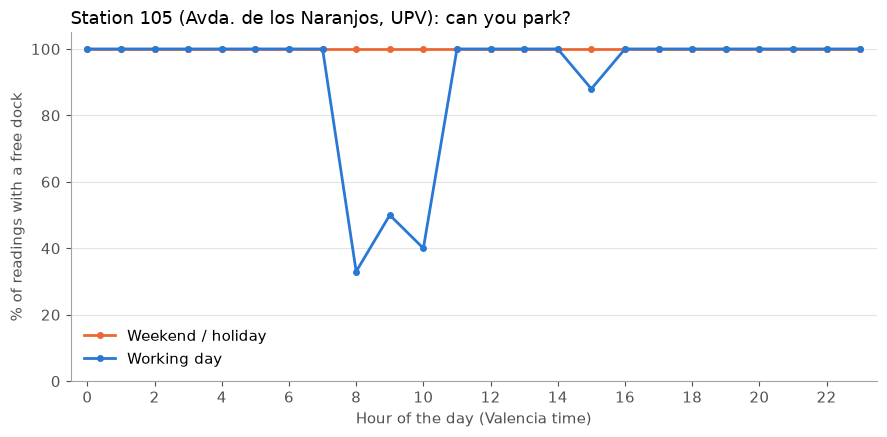

In [ ]:
fig, ax = plt.subplots()
for day_type, g in profile_105.groupby("day_type"):
    ax.plot(g["local_hour"], g["pct_dock"], color=COLOR[day_type], linewidth=2, marker="o", markersize=4,
            label=LABEL[day_type])

# Legend in the empty lower area: both lines end at 100%, so labels at the line ends would overlap
ax.legend(loc="lower left", frameon=False)

ax.set_ylim(0, 105)
ax.set_xlim(-0.5, 23.5)
ax.set_xticks(range(0, 24, 2))
ax.set_xlabel("Hour of the day (Valencia time)")
ax.set_ylabel("% of readings with a free dock")
ax.set_title("Station 105 (Avda. de los Naranjos, UPV): can you park?", loc="left")
fig.tight_layout()
plt.show()

**Findings** (data up to 14 October: 6 working days, ~12 readings per hour)

- **Weekends and holidays:** the station never has bikes in the morning (0%) and always has free docks. Nobody rides to campus on non-teaching days.
- **Working days:** before 8:00 there is always a free dock (100% at 6:00 and 7:00). At 8:00 it drops to **33%**, stays low until 10:00 (50%, 40%) and is back to 100% at 11:00. Bikes follow the opposite curve: 18% at 6:00, 100% from 8:00. The station fills up with the morning arrival peak.
- **Practical answer:** arriving before 8:00, there was a free dock on every observed day; arriving between 8:00 and 11:00, only about 1 time in 3 to 2.
- **Caveat:** each percentage rests on ~12 readings, so one reading moves it by ~8 points. The pattern (full between 8:00 and 11:00) is clear; the exact percentages are not.

### 4.2 A real trip: station 74 (Mercado Algirós) to station 105 (UPV)

A trip works only if there is a bike at the origin **and** a free dock at the destination.

The tempting shortcut is to multiply the two percentages. That assumes the two stations are independent, which may not hold: a busy morning can empty the origin and fill the destination at the same time.

The correct way is to pair the readings of both stations taken in the **same 30-minute slot** and count how often both conditions held together. The ride takes a few minutes, so both ends are read in the same slot (an approximation).

In [104]:
ORIGIN, DESTINATION = 74, 105

origin = clean.loc[clean["station_id"] == ORIGIN, ["slot", "day_type", "local_hour", "bikes"]]
destination = clean.loc[clean["station_id"] == DESTINATION, ["slot", "free_docks"]]

# Inner join on the slot: keep only moments where both stations have a reading
trips = origin.merge(destination, on="slot", how="inner")
trips["bike_ok"] = trips["bikes"] >= 1
trips["dock_ok"] = trips["free_docks"] >= 1
trips["trip_ok"] = trips["bike_ok"] & trips["dock_ok"]

trip_table = (
    trips[trips["day_type"] == "workday"]
    .groupby("local_hour")
    .agg(
        readings=("trip_ok", "size"),
        pct_bike=("bike_ok", "mean"),
        pct_dock=("dock_ok", "mean"),
        pct_trip=("trip_ok", "mean"),
    )
)
# The shortcut, for comparison: multiply the two probabilities
trip_table["pct_naive"] = trip_table["pct_bike"] * trip_table["pct_dock"]

(trip_table[["pct_bike", "pct_dock", "pct_naive", "pct_trip"]] * 100).round(0).join(trip_table["readings"]).loc[6:11]

,pct_bike,pct_dock,pct_naive,pct_trip,readings
local_hour,,,,,
6,100.0,100.0,100.0,100.0,11
7,100.0,100.0,100.0,100.0,12
8,83.0,33.0,28.0,33.0,12
9,83.0,50.0,42.0,42.0,12
10,80.0,40.0,32.0,40.0,10
11,90.0,100.0,90.0,90.0,10


**Findings**

- **The origin is not the problem.** Station 74 had a bike in 80-90% of readings at every morning hour.
- **The destination decides the trip.** `pct_trip` is almost identical to `pct_dock` (33% vs 33% at 8:00, 40% vs 40% at 10:00): whether the trip works depends almost entirely on finding a dock at the UPV.
- **Multiplying underestimates.** The shortcut gives 28% at 8:00 and 32% at 10:00; the real paired figures are 33% and 40%. The two stations are not independent: in this sample, when station 105 had room, station 74 almost always had a bike too. Multiplying assumes independence and therefore gets the answer wrong.
- **Caveat:** 10-12 paired readings per hour. The gap between naive and real is one or two readings, so it shows the method matters, not a precise effect size.
- **Answer to the project question:** for this trip on a working day, leaving to arrive before 8:00 worked every time; arriving at 8:00 works about 1 time in 3.

### 4.3 Where is it hardest to park at 8:00 on a working day?

Stations with fewer than 8 readings in this slot are left out: too few to say anything.

In [105]:
MIN_READINGS = 8

at_8 = clean[(clean["day_type"] == "workday") & (clean["local_hour"] == 8)]
by_station = (
    at_8.groupby("station_id")
    .agg(readings=("free_docks", "size"),
         pct_dock=("free_docks", lambda x: (x >= 1).mean() * 100))
    .query("readings >= @MIN_READINGS")
    .join(stations.set_index("station_id")["label"])
    .round(0)
)
# Several stations share a name (e.g. four "Avda. De Los Naranjos"): add the ID so each bar is unique
by_station["label"] = by_station["label"] + " (" + by_station.index.astype(str) + ")"
hardest = by_station.sort_values("pct_dock").head(10)
hardest

,readings,pct_dock,label
station_id,,,
111,12,8.0,Universidad Politecnica – Junto Pistas Deporti...
114,12,17.0,Adolfo Suarez (114)
113,12,25.0,Ets Caminos (113)
105,12,33.0,Avda. De Los Naranjos (105)
95,12,33.0,Avda. De Los Naranjos (95)
110,12,42.0,Kisshomaru (110)
109,12,42.0,Avda. Naranjos (109)
106,12,42.0,Avda. De Los Naranjos (106)
112,12,42.0,Avda. De Los Naranjos (112)


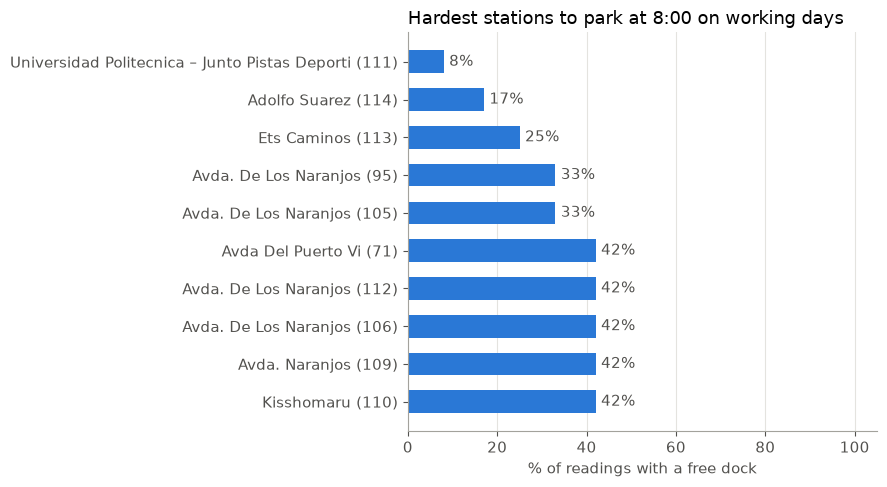

In [106]:
fig, ax = plt.subplots(figsize=(9, 5))
plot_data = hardest.sort_values("pct_dock", ascending=False)  # lowest at the top
bars = ax.barh(plot_data["label"], plot_data["pct_dock"], color="#2a78d6", height=0.6)
ax.bar_label(bars, fmt="%.0f%%", padding=4, color="#52514e")

ax.set_xlim(0, 105)
ax.set_axisbelow(True)
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
ax.set_xlabel("% of readings with a free dock")
ax.set_title("Hardest stations to park at 8:00 on working days", loc="left")
fig.tight_layout()
plt.show()

**Findings**

- **The hardest stations are concentrated around the university.** At least 7 of the 10 are on Avda. de los Naranjos or inside the UPV campus (111, 113, 105, 95, 106, 112, 109). The UPV is one of the city's biggest morning destinations: many people arrive by bike and few leave before mid-morning.
- **Station 105 is 4th (33%)**, so the problem is not specific to it: the nearby stations are just as full (33-42%). Riding on to the next station on the same avenue does not solve it.
- **Caveats:** 12 readings per station, so a difference of one reading is ~8 points; the order among the stations tied at 42% is arbitrary. Some names are truncated in the source data (e.g. "Avda Del Puerto Vi").

## 5. Conclusions and limitations

### Answer to the question

Data up to 14 October 2026 (6 working days).

- **Parking at the UPV (station 105) on a working day:** before 8:00 there was a free dock on every observed day. Between 8:00 and 11:00 there was one in only 33-50% of readings. From 11:00 it is free again.
- **Weekends and holidays:** the station always has free docks but never has bikes in the morning.
- **Trip 74 (Mercado Algirós) to 105 (UPV):** the origin almost always has a bike (80-90%); the trip fails at the destination. Arriving before 8:00 worked every time; arriving at 8:00 worked about 1 time in 3.
- **The whole UPV area saturates at 8:00:** at least 7 of the 10 hardest stations in the city are on Avda. de los Naranjos or inside the campus. Riding on to the next station does not help.
- **Method:** multiplying the probability of a bike at the origin by that of a dock at the destination underestimates the real chance of a successful trip, because the two stations are not independent. Paired readings give the right figure.

### Data work behind it

- Six quality checks on the raw data (section 2), each ending in a documented decision.
- Five cleaning rules (section 3) that keep 87% of the readings, with the rows removed at each step logged and verified with assertions and a cross-check against SQL.
- Problems found and handled: irregular collection before 3 October, extra pipeline runs, a station stale since 15 September, about a dozen city-centre stations out of service around 9 October, and an API `is_open` flag that is always `True`.

### Limitations

1. **Small sample.** About two weeks of data, only 6 working days (the period includes two holidays), ~12 readings per station and hour. One reading moves a percentage by ~8 points. The patterns are clear; the exact percentages are not.
2. **Atypical period.** 9 October (holiday) and 8-10 October, when about a dozen city-centre stations were out of service. The cause (the 9 d'Octubre celebrations) is a hypothesis, not confirmed by an official source.
3. **Out-of-service readings are excluded.** The analysis describes the system working normally. For a rider, a station out of service also means "cannot park"; the SQL view in `sql/setup.sql` keeps those readings and counts them that way.
4. **Snapshots, not continuous data.** One reading per station every 30 minutes; what happens in between is unknown. A trip is approximated by reading both stations in the same 30-minute slot.
5. **Gaps in collection.** The Valenbisi API failed several times on 13 October; missing runs are missing data, not zeros.
6. **Source data quirks.** `is_open` is unreliable and some station names are truncated.
7. **Historical frequencies, not predictions.** Nothing here models weather, exams, events or term calendars.

### Next steps

- Re-run this notebook with 4-6 weeks of data: it is fully reproducible and the figures will become more reliable without changing any code.
- Turn the out-of-service rule from section 2.5 into a daily monitoring check in the pipeline.
- Build a small page where a user picks origin, destination and time and gets the paired probability from section 4.2.